In [31]:
!tar -xzf ciciot2023-ids.tar.gz
%cd ciciot2023-ids
!pip install -r requirements.txt

tar (child): ciciot2023-ids.tar.gz: Cannot open: No such file or directory
tar (child): Error is not recoverable: exiting now
tar: Child returned status 2
tar: Error is not recoverable: exiting now
[Errno 2] No such file or directory: 'ciciot2023-ids'
/content/ciciot2023-ids


In [32]:
!cp "/content/drive/MyDrive/CSV.zip" "/content/ciciot2023-ids/data/raw/CICIoT2023"


In [33]:
!pip install -q -U xgboost lightgbm pyarrow scikit-learn pandas matplotlib joblib tqdm
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader || echo "No GPU detected (XGBoost will use CPU)"

Tesla T4, 15360 MiB


In [34]:
import os, re, json, time, math, warnings, subprocess, tempfile, zipfile, shutil
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

REPO    = Path(os.environ.get('CIC_REPO', '/content/ciciot2023-ids'))
RAW_DIR = Path(os.environ.get('CIC_RAW', str(REPO / 'data/raw/CICIoT2023')))
REPORTS, MODELS, CACHE = REPO/'reports', REPO/'models', REPO/'data/processed'
for p in (REPORTS, MODELS, CACHE): p.mkdir(parents=True, exist_ok=True)

# ---- knobs you may change -------------------------------------------------
SEED             = 42
CAP_PER_ATTACK   = 60_000     # sampled rows per attack label (raise to 100_000+ if you have time)
CAP_BENIGN       = 400_000    # sampled rows for BenignTraffic
RF_MAX_TRAIN     = 600_000    # RandomForest / LR training-row cap (CPU speed)
RUN_LIGHTGBM     = True
RUN_FINEGRAINED  = True
FORCE_RESAMPLE   = False      # True = ignore the cached parquet and sample again
BENIGN_LABEL     = 'BenignTraffic'
# ----------------------------------------------------------------------------

HAS_GPU = shutil.which('nvidia-smi') is not None and subprocess.run(['nvidia-smi'], capture_output=True).returncode == 0
import xgboost as xgb
XGB_MAJOR = int(xgb.__version__.split('.')[0])
def xgb_dev():
    if not HAS_GPU: return {'tree_method': 'hist'}
    return {'device': 'cuda', 'tree_method': 'hist'} if XGB_MAJOR >= 2 else {'tree_method': 'gpu_hist'}

print('GPU:', HAS_GPU, '| xgboost', xgb.__version__, '| CPU cores:', os.cpu_count())
print('RAW_DIR:', RAW_DIR)

GPU: True | xgboost 3.4.1 | CPU cores: 2
RAW_DIR: /content/ciciot2023-ids/data/raw/CICIoT2023


In [35]:
def find_csvs():
    return sorted(p for p in RAW_DIR.rglob('*.pcap.csv') if '.ipynb_checkpoints' not in p.parts)

files = find_csvs()
if not files:
    cands = [p for p in list(RAW_DIR.glob('*')) + list(Path('/content').glob('*'))
             if p.is_file() and p.stat().st_size > 1_000_000 and zipfile.is_zipfile(p)]
    if not cands:
        raise SystemExit('No *.pcap.csv files and no valid zip found. Put the dataset in ' + str(RAW_DIR))
    print('Extracting', cands[0], '...')
    with zipfile.ZipFile(cands[0]) as z: z.extractall(RAW_DIR)
    files = find_csvs()

# drop exact duplicates (same file name + same size), e.g. if the zip was extracted twice
seen, uniq = set(), []
for p in files:
    key = (p.name, p.stat().st_size)
    if key in seen: continue
    seen.add(key); uniq.append(p)
print(f'{len(files)} files found, {len(files)-len(uniq)} duplicates removed -> {len(uniq)} files')
files = uniq

# header check: all files must share the same feature columns and have no label column
def read_header(p): return tuple(c.strip() for c in pd.read_csv(p, nrows=0).columns)
headers = {p: read_header(p) for p in files}
common = Counter(headers.values()).most_common(1)[0][0]
FEATURES = [c for c in common]
bad = [p for p, h in headers.items() if h != common or 'label' in [c.lower() for c in h]]
if bad:
    print(f'WARNING: skipping {len(bad)} file(s) with a different header, e.g.', [b.name for b in bad[:5]])
files = [p for p in files if p not in bad]
print(len(FEATURES), 'features:', FEATURES)

309 files found, 0 duplicates removed -> 309 files
39 features: ['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance']


In [36]:
def label_from_path(p):
    name = re.sub(r'\.pcap\.csv$', '', Path(p).name)
    return re.sub(r'\d+$', '', name)            # BenignTraffic3 -> BenignTraffic

def label_to_family(label):
    l = label.lower()
    if 'benign' in l:                                   return 'Benign'
    if l.startswith('ddos'):                            return 'DDoS'
    if l.startswith('dos'):                             return 'DoS'
    if l.startswith('mirai'):                           return 'Mirai'
    if l.startswith('recon') or 'vulnerabilityscan' in l: return 'Recon'
    if 'spoofing' in l or l.startswith('mitm'):         return 'Spoofing'
    if 'bruteforce' in l or 'dictionary' in l:          return 'BruteForce'
    if any(x in l for x in ['sqlinjection','xss','commandinjection','browserhijacking','backdoor','uploading']):
        return 'Web-based'
    return 'Other'

def count_rows(p):
    out = subprocess.run(['wc', '-l', str(p)], capture_output=True, text=True).stdout.split()[0]
    return max(int(out) - 1, 0)

info = pd.DataFrame({'path': files})
info['label']  = info.path.map(label_from_path)
info['family'] = info.label.map(label_to_family)
info['rows']   = Parallel(n_jobs=min(8, os.cpu_count() or 1))(delayed(count_rows)(p) for p in tqdm(files, desc='counting rows'))

summary = info.groupby(['family', 'label']).agg(files=('path', 'count'), rows=('rows', 'sum')).reset_index()
print(summary.to_string(index=False))
print(f"\nTOTAL rows: {info.rows.sum():,} | labels: {info.label.nunique()} (CICIoT2023 normally has 34) | families: {info.family.nunique()}")
assert 'Other' not in set(info.family), 'Unmapped labels -> add them to label_to_family(): ' + str(sorted(info[info.family=="Other"].label.unique()))

counting rows:   0%|          | 0/309 [00:00<?, ?it/s]

    family                   label  files    rows
    Benign           BenignTraffic      4 1098191
BruteForce    DictionaryBruteForce      1   13064
      DDoS  DDoS-ACK_Fragmentation     13  285075
      DDoS        DDoS-HTTP_Flood-      1   28790
      DDoS         DDoS-ICMP_Flood     27 7200501
      DDoS DDoS-ICMP_Fragmentation     20  452490
      DDoS       DDoS-PSHACK_Flood     16 4094772
      DDoS        DDoS-RSTFINFlood     16 4045279
      DDoS          DDoS-SYN_Flood     16 4059179
      DDoS          DDoS-SlowLoris      1   23426
      DDoS DDoS-SynonymousIP_Flood     14 3598133
      DDoS          DDoS-TCP_Flood     18 4497649
      DDoS          DDoS-UDP_Flood     21 5412231
      DDoS  DDoS-UDP_Fragmentation     13  286925
       DoS          DoS-HTTP_Flood      2   71861
       DoS           DoS-SYN_Flood      8 2028836
       DoS           DoS-TCP_Flood     11 2671430
       DoS           DoS-UDP_Flood     17 3072990
     Mirai      Mirai-greeth_flood     29  991834


In [37]:
def sample_one(path, features, n_rows, quota, seed):
    rng = np.random.default_rng(seed)
    mask = np.zeros(n_rows + 16, dtype=bool)
    if quota >= n_rows: mask[:n_rows] = True
    else: mask[rng.choice(n_rows, quota, replace=False)] = True
    parts, pos = [], 0
    for ch in pd.read_csv(path, chunksize=500_000, low_memory=False, encoding_errors='replace'):
        ch.columns = [c.strip() for c in ch.columns]
        m = mask[pos:pos + len(ch)]
        if len(m) < len(ch): m = np.pad(m, (0, len(ch) - len(m)))
        pos += len(ch)
        if m.any():
            parts.append(ch.loc[m, features].apply(pd.to_numeric, errors='coerce').astype('float32'))
    if not parts: return None
    df = pd.concat(parts, ignore_index=True)
    df['_rp'] = (np.arange(len(df)) + 0.5) / len(df)       # relative position inside the file
    return df

cache_file = CACHE / 'sampled_ciciot2023.parquet'
if cache_file.exists() and not FORCE_RESAMPLE:
    df = pd.read_parquet(cache_file)
    print('Loaded cached sample:', cache_file, df.shape)
else:
    cap = lambda lab: CAP_BENIGN if lab == BENIGN_LABEL else CAP_PER_ATTACK
    label_rows = info.groupby('label').rows.sum()
    info['quota'] = [max(1, int(round(min(cap(r.label), label_rows[r.label]) * r.rows / max(label_rows[r.label], 1))))
                     if r.rows > 0 else 0 for r in info.itertuples()]
    jobs = [(r.path, r.rows, r.quota, i) for i, r in enumerate(info.itertuples()) if r.rows > 0]
    t0 = time.time()
    gen = Parallel(n_jobs=min(4, os.cpu_count() or 1), return_as='generator')(
        delayed(sample_one)(p, FEATURES, n, q, SEED + i) for p, n, q, i in jobs)
    frames, labs = [], []
    for (p, n, q, i), d in zip(jobs, tqdm(gen, total=len(jobs), desc='sampling files')):
        if d is None: continue
        d['label'] = label_from_path(p); frames.append(d)
    df = pd.concat(frames, ignore_index=True)
    print(f'Sampled {len(df):,} rows in {(time.time()-t0)/60:.1f} min')
    df[FEATURES] = df[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0).astype('float32')
    before = len(df)
    df = df.drop_duplicates(subset=FEATURES + ['label']).reset_index(drop=True)
    print(f'Removed {before-len(df):,} exact duplicate rows')
    df['split'] = np.where(df._rp < .70, 'train', np.where(df._rp < .85, 'val', 'test'))
    df = df.drop(columns='_rp')
    df.to_parquet(cache_file)
    print('Cached ->', cache_file)

df['family']    = df.label.map(label_to_family)
df['is_attack'] = (df.label != BENIGN_LABEL).astype('int8')

tab = df.pivot_table(index=['family', 'label'], columns='split', values='is_attack', aggfunc='size', fill_value=0)
tab['total'] = tab.sum(axis=1)
print(tab[['train', 'val', 'test', 'total']].to_string())

Loaded cached sample: /content/ciciot2023-ids/data/processed/sampled_ciciot2023.parquet (1713262, 41)
split                                train    val   test   total
family     label                                                
Benign     BenignTraffic            279340  59830  59826  398996
BruteForce DictionaryBruteForce       9144   1959   1959   13062
DDoS       DDoS-ACK_Fragmentation    41957   8985   8986   59928
           DDoS-HTTP_Flood-          20153   4318   4319   28790
           DDoS-ICMP_Flood           29081   6220   6207   41508
           DDoS-ICMP_Fragmentation   41955   8994   8993   59942
           DDoS-PSHACK_Flood         32683   6957   6880   46520
           DDoS-RSTFINFlood          30102   6400   6414   42916
           DDoS-SYN_Flood            32978   6907   6877   46762
           DDoS-SlowLoris            16398   3514   3514   23426
           DDoS-SynonymousIP_Flood   30790   6474   6343   43607
           DDoS-TCP_Flood            29771   6232   6

{'train': 1201950, 'val': 255701, 'test': 255611}


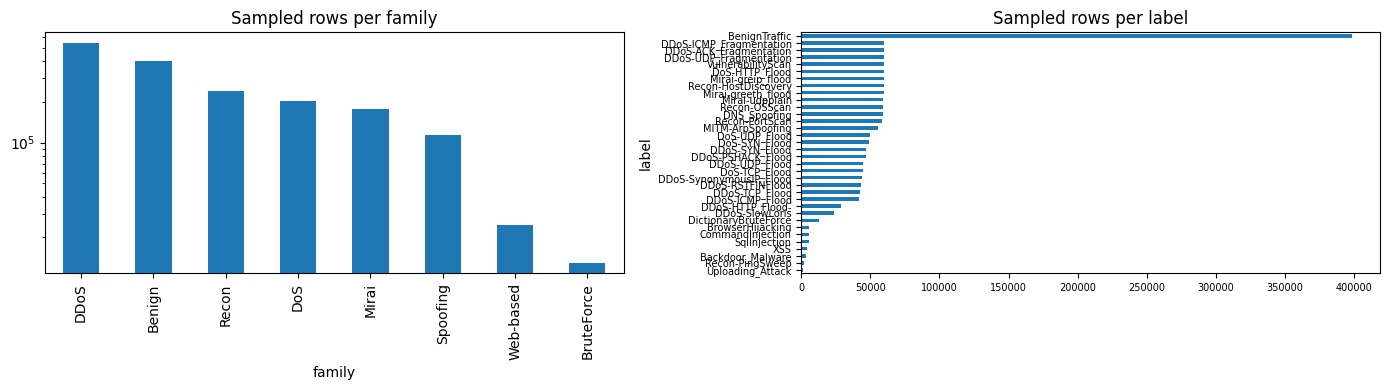

In [38]:
tr, va, te = (df[df.split == s] for s in ('train', 'val', 'test'))
# every label must appear in train; drop val/test rows of labels unseen in train (should be none)
train_labels = set(tr.label)
va, te = va[va.label.isin(train_labels)], te[te.label.isin(train_labels)]
print({k: len(v) for k, v in dict(train=tr, val=va, test=te).items()})

Xtr, Xva, Xte = (d[FEATURES].to_numpy(np.float32) for d in (tr, va, te))

fam = df.groupby('family').size().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
fam.plot.bar(ax=ax[0], title='Sampled rows per family'); ax[0].set_yscale('log')
df.groupby('label').size().sort_values().plot.barh(ax=ax[1], title='Sampled rows per label', fontsize=7)
plt.tight_layout(); plt.show()

In [39]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             balanced_accuracy_score, confusion_matrix, classification_report)
from xgboost import XGBClassifier
try:
    import lightgbm as lgb
    from lightgbm import LGBMClassifier
except Exception as e:
    RUN_LIGHTGBM = False; print('LightGBM unavailable:', e)

def full_metrics(y_true, y_pred, n_classes):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(n_classes))
    tp = np.diag(cm).astype(float); fn = cm.sum(1) - tp; fp = cm.sum(0) - tp; tn = cm.sum() - tp - fn - fp
    with np.errstate(all='ignore'):
        fpr = np.where(fp + tn > 0, fp / (fp + tn), 0.); fnr = np.where(tp + fn > 0, fn / (tp + fn), 0.)
    present = cm.sum(1) > 0
    m = dict(accuracy=accuracy_score(y_true, y_pred),
             precision=precision_score(y_true, y_pred, average='macro', zero_division=0),
             recall=recall_score(y_true, y_pred, average='macro', zero_division=0),
             f1_macro=f1_score(y_true, y_pred, average='macro', zero_division=0),
             f1_weighted=f1_score(y_true, y_pred, average='weighted', zero_division=0),
             balanced_acc=balanced_accuracy_score(y_true, y_pred))
    if n_classes == 2:      # attack = positive class
        m.update(precision=precision_score(y_true, y_pred, zero_division=0),
                 recall=recall_score(y_true, y_pred, zero_division=0), FPR=fpr[1], FNR=fnr[1])
    else:                   # macro over classes present in the test set
        m.update(FPR=fpr[present].mean(), FNR=fnr[present].mean())
    return m, cm

def to_edge(model):
    """CPU, single-thread settings, so latency numbers resemble a small edge device."""
    try:
        if type(model).__name__.startswith('XGB'):
            model.set_params(device='cpu') if XGB_MAJOR >= 2 else model.set_params(tree_method='hist')
        if 'n_jobs' in model.get_params(deep=False): model.set_params(n_jobs=1)
    except Exception as e: print('  (to_edge note)', e)

def model_size_mb(model):
    with tempfile.NamedTemporaryFile(suffix='.joblib') as f:
        import joblib; joblib.dump(model, f.name); return os.path.getsize(f.name) / 2**20

def benchmark(model, X, n_single=200, n_batch=20000):
    to_edge(model)
    for i in range(5): model.predict(X[i:i+1])
    lat = []
    for i in range(n_single):
        t = time.perf_counter(); model.predict(X[i:i+1]); lat.append((time.perf_counter() - t) * 1000)
    Xb = X[:n_batch]; t = time.perf_counter(); model.predict(Xb); dt = time.perf_counter() - t
    return dict(lat_ms_mean=float(np.mean(lat)), lat_ms_p95=float(np.percentile(lat, 95)),
                throughput_fps=len(Xb) / dt, size_mb=model_size_mb(model))

def subsample(X, y, n, seed=SEED):
    if len(X) <= n: return X, y
    idx = np.random.default_rng(seed).choice(len(X), n, replace=False); return X[idx], y[idx]

def build_models(task, n_classes):
    multi = n_classes > 2
    trees = {'binary': 100, 'family': 100, 'finegrained': 60}[task]
    ev = 'mlogloss' if multi else 'logloss'
    ms = {}
    if task == 'binary':
        ms['LogisticRegression'] = Pipeline([('scale', StandardScaler()),
            ('clf', LogisticRegression(max_iter=200, class_weight='balanced'))])
        ms['DecisionTree'] = DecisionTreeClassifier(max_depth=20, min_samples_leaf=2, class_weight='balanced', random_state=SEED)
    ms['RandomForest'] = RandomForestClassifier(n_estimators=trees, max_depth=20 if task != 'finegrained' else 18,
        min_samples_leaf=2, n_jobs=-1, class_weight='balanced_subsample', random_state=SEED)
    ms['XGBoost'] = XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1 if not multi else 0.15,
        subsample=0.8, colsample_bytree=0.8, eval_metric=ev, early_stopping_rounds=20, random_state=SEED, **xgb_dev())
    if RUN_LIGHTGBM and task != 'finegrained':
        ms['LightGBM'] = LGBMClassifier(n_estimators=400, num_leaves=63, learning_rate=0.1, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.8, class_weight='balanced', n_jobs=-1, random_state=SEED, verbose=-1)
    return ms

def fit_one(name, model, X, y, Xv, yv, multi):
    cap = RF_MAX_TRAIN if name in ('RandomForest', 'LogisticRegression', 'LightGBM') else len(X)
    X, y = subsample(X, y, cap)
    if name == 'XGBoost':
        w = compute_sample_weight('balanced', y); w = np.sqrt(w) if multi else w
        model.fit(X, y, sample_weight=w, eval_set=[(Xv, yv)], verbose=False)
    elif name == 'LightGBM':
        model.fit(X, y, eval_set=[(Xv, yv)], callbacks=[lgb.early_stopping(20, verbose=False)])
    else:
        model.fit(X, y)

def run_task(task, ytr, yva, yte, class_names, tag):
    n = len(class_names); multi = n > 2
    models, rows, cms, fitted = build_models(task, n), [], {}, {}
    for name, model in models.items():
        print(f'\n[{tag}] training {name} ...', flush=True)
        t = time.time(); fit_one(name, model, Xtr, ytr, Xva, yva, multi); train_s = time.time() - t
        yp = model.predict(Xte)
        m, cm = full_metrics(yte, yp, n)
        m.update(model=name, train_s=train_s); m.update(benchmark(model, Xte))
        rows.append(m); cms[name] = cm; fitted[name] = model
        print(f"   macro-F1 {m['f1_macro']:.4f} | recall {m['recall']:.4f} | FPR {m['FPR']:.4f} | "
              f"p95 {m['lat_ms_p95']:.2f} ms | {m['size_mb']:.1f} MB | train {train_s:.0f}s")
    res = pd.DataFrame(rows).set_index('model')[['accuracy','precision','recall','f1_macro','f1_weighted','balanced_acc',
                                                'FPR','FNR','train_s','lat_ms_mean','lat_ms_p95','throughput_fps','size_mb']]
    res.round(4).to_csv(REPORTS / f'comparison_{tag}.csv')
    return res, cms, fitted

def pick_best(res, tol=0.002):
    """Best accuracy/performance trade-off: among models within `tol` macro-F1 of the best, take the fastest (p95 latency)."""
    ok = res[res.f1_macro >= res.f1_macro.max() - tol]
    return ok.lat_ms_p95.idxmin()

def plot_cm(cm, names, title, fname, normalize=True):
    c = cm / np.maximum(cm.sum(1, keepdims=True), 1) if normalize else cm
    s = max(5, 0.38 * len(names)); fig, ax = plt.subplots(figsize=(s + 2, s + 1))
    im = ax.imshow(c, cmap='Blues', vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
    ax.set_xticklabels(names, rotation=90, fontsize=7 if len(names) > 12 else 10)
    ax.set_yticklabels(names, fontsize=7 if len(names) > 12 else 10)
    if len(names) <= 12:
        for i in range(len(names)):
            for j in range(len(names)): ax.text(j, i, f'{c[i,j]:.2f}' if normalize else int(c[i,j]), ha='center', va='center', fontsize=8)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title); fig.colorbar(im, shrink=.7)
    plt.tight_layout(); fig.savefig(REPORTS / fname, dpi=130); plt.show()
print('helpers ready')

helpers ready


In [40]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Data Distribution Visualization Helpers ---
def plot_feature_distributions(dataframe, features_to_plot=None, n_cols=3):
    """Plots the distribution of selected features grouped by attack vs benign status."""
    if features_to_plot is None:
        # Select a representative mix of interesting features
        features_to_plot = ['Header_Length', 'Protocol Type', 'Rate', 'Tot size', 'IAT', 'Variance']

    n_features = len(features_to_plot)
    n_rows = (n_features + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = axes.flatten()

    for i, col in enumerate(features_to_plot):
        if col in dataframe.columns:
            sns.kdeplot(
                data=dataframe,
                x=col,
                hue='is_attack',
                common_norm=False,
                shade=True,
                alpha=0.5,
                ax=axes[i]
            )
            axes[i].set_title(f'Distribution of {col}')
            axes[i].set_yscale('log') # Many network parameters are highly skewed
        else:
            axes[i].axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

# --- 2. PyTorch Deep Learning Models (ANN & CNN-1D) ---
class TabularANN(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(TabularANN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.net(x)

class TabularCNN1D(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(TabularCNN1D, self).__init__()
        # Reshape tabular input to (batch, channels, length) -> (batch, 1, input_dim)
        self.conv = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(8)
        )
        self.fc = nn.Sequential(
            nn.Linear(32 * 8, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        # x shape: [batch, input_dim] -> conv expects [batch, 1, input_dim]
        x = x.unsqueeze(1)
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

# Wrapper helper to train and predict using PyTorch models inside your sklearn pipeline structure
class PyTorchTabularWrapper:
    def __init__(self, model_class, input_dim, output_dim, epochs=10, batch_size=512, lr=0.001, is_cnn=False):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.model = model_class(input_dim, output_dim).to(self.device)
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.output_dim = output_dim
        self.is_cnn = is_cnn

    def fit(self, X, y, eval_set=None, callbacks=None):
        # Simple scaling fallback
        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0) + 1e-8
        X_scaled = (X - self.mean) / self.std

        tensor_x = torch.tensor(X_scaled, dtype=torch.float32)
        tensor_y = torch.tensor(y, dtype=torch.long if self.output_dim > 2 else torch.float32)

        dataset = TensorDataset(tensor_x, tensor_y)
        loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        criterion = nn.CrossEntropyLoss() if self.output_dim > 2 else nn.BCEWithLogitsLoss()
        optimizer = optim.AdamW(self.model.parameters(), lr=self.lr, weight_decay=1e-4)

        self.model.train()
        for epoch in range(self.epochs):
            for bx, by in loader:
                bx, by = bx.to(self.device), by.to(self.device)
                optimizer.zero_grad()
                out = self.model(bx)
                if self.output_dim == 2 and len(out.shape) > 1 and out.shape[1] == 1:
                    out = out.squeeze(1)
                loss = criterion(out, by)
                loss.backward()
                optimizer.step()

    def predict_proba(self, X):
        self.model.eval()
        X_scaled = (X - self.mean) / self.std
        tensor_x = torch.tensor(X_scaled, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            logits = self.model(tensor_x)
            if self.output_dim > 2:
                probs = torch.softmax(logits, dim=1).cpu().numpy()
            else:
                probs_pos = torch.sigmoid(logits).cpu().numpy().reshape(-1, 1)
                probs = np.hstack([1 - probs_pos, probs_pos])
        return probs

    def predict(self, X):
        probs = self.predict_proba(X)
        return probs.argmax(axis=1) if self.output_dim > 2 else (probs[:, 1] >= 0.5).astype(int)

    def get_params(self, deep=True):
        return {'epochs': self.epochs, 'batch_size': self.batch_size, 'lr': self.lr}

    def set_params(self, **params):
        for param, val in params.items():
            setattr(self, param, val)
        return self

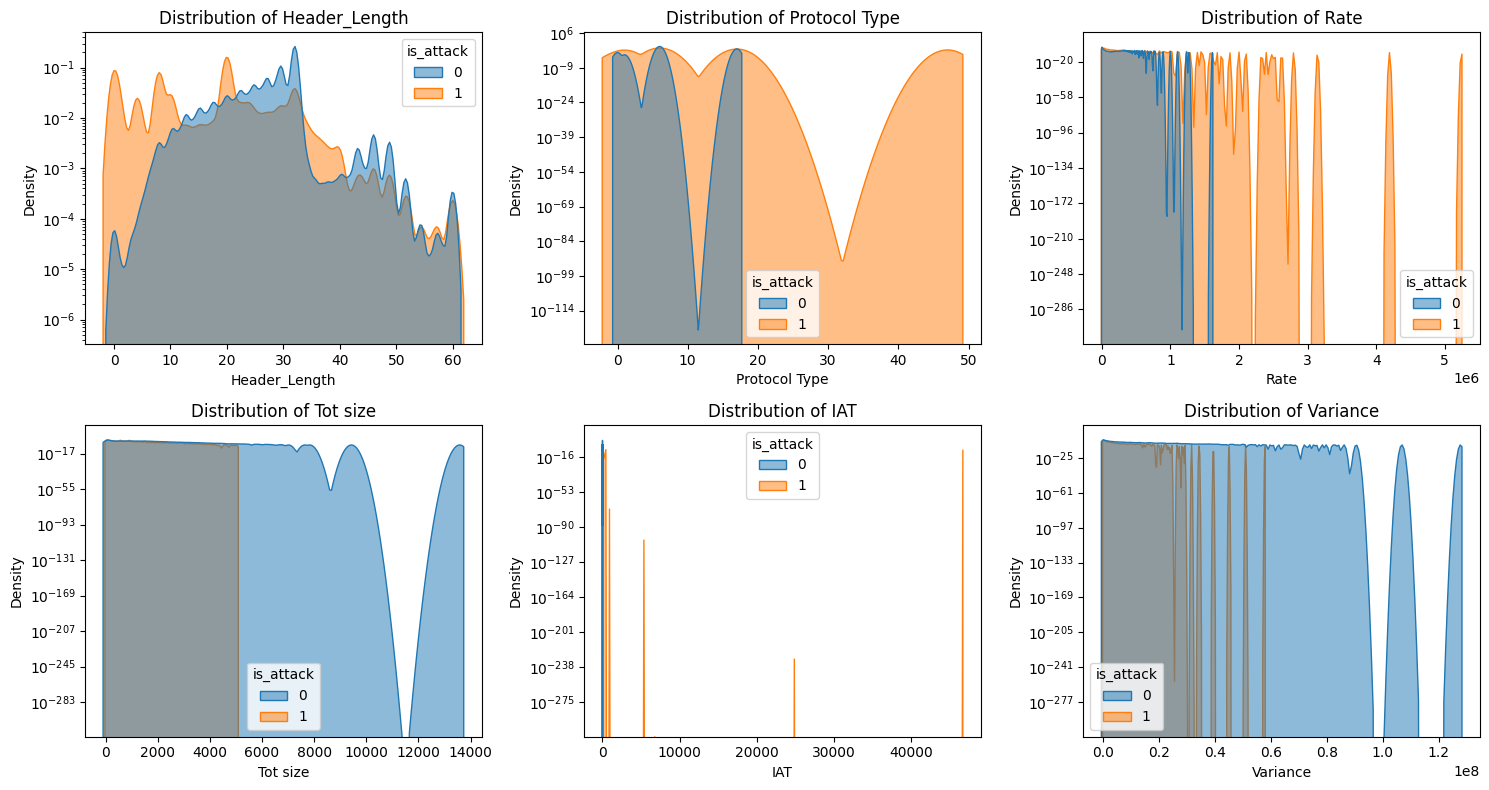

In [41]:
# Call the distribution plotting helper on the dataframe
plot_feature_distributions(df)

Now, we will modify the `build_models` function to seamlessly append our new Deep Learning `ANN` and `CNN1D` models into the experiment suite.

In [42]:
# Check if we have already saved the true original build_models to prevent infinite recursion on multiple executions
if 'original_build_models' not in globals() or build_models.__name__ != 'build_models_with_dl':
    original_build_models = build_models

def build_models_with_dl(task, n_classes):
    # Call the original model builder to get ML baselines
    ms = original_build_models(task, n_classes)

    # Add the Deep Learning ANN and CNN-1D models to the suite
    ms['PyTorch_ANN'] = PyTorchTabularWrapper(
        model_class=TabularANN,
        input_dim=len(FEATURES),
        output_dim=n_classes if n_classes > 2 else 1,
        epochs=8,
        batch_size=1024
    )
    ms['PyTorch_CNN1D'] = PyTorchTabularWrapper(
        model_class=TabularCNN1D,
        input_dim=len(FEATURES),
        output_dim=n_classes if n_classes > 2 else 1,
        epochs=8,
        batch_size=1024,
        is_cnn=True
    )
    return ms

build_models = build_models_with_dl
print("build_models updated safely to include PyTorch ANN & CNN1D!")

build_models updated safely to include PyTorch ANN & CNN1D!


In [43]:
ytr_b, yva_b, yte_b = (d.is_attack.to_numpy() for d in (tr, va, te))
bin_names = ['Benign', 'Attack']

# Quick patch for PyTorchTabularWrapper fit function to squeeze predicted output when running binary training
import torch.nn as nn

def patched_fit(self, X, y, eval_set=None, callbacks=None):
    self.mean = X.mean(axis=0)
    self.std = X.std(axis=0) + 1e-8
    X_scaled = (X - self.mean) / self.std

    tensor_x = torch.tensor(X_scaled, dtype=torch.float32)
    tensor_y = torch.tensor(y, dtype=torch.long if self.output_dim > 2 else torch.float32)

    dataset = TensorDataset(tensor_x, tensor_y)
    loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

    criterion = nn.CrossEntropyLoss() if self.output_dim > 2 else nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(self.model.parameters(), lr=self.lr, weight_decay=1e-4)

    self.model.train()
    for epoch in range(self.epochs):
        for bx, by in loader:
            bx, by = bx.to(self.device), by.to(self.device)
            optimizer.zero_grad()
            out = self.model(bx)

            # Squeeze output to match target shape [batch_size] instead of [batch_size, 1]
            if out.dim() > 1 and out.size(1) == 1:
                out = out.squeeze(1)
            if out.dim() == 1 and by.dim() > 1 and by.size(1) == 1:
                by = by.squeeze(1)

            loss = criterion(out, by)
            loss.backward()
            optimizer.step()

# Apply patch dynamically to solve shape incompatibility
PyTorchTabularWrapper.fit = patched_fit

res_bin, cms_bin, fit_bin = run_task('binary', ytr_b, yva_b, yte_b, bin_names, 'binary')
best_bin = pick_best(res_bin)
print('\n', res_bin.round(4).to_string())
print('\nBest trade-off model (binary):', best_bin)


[binary] training LogisticRegression ...
   macro-F1 0.8073 | recall 0.7958 | FPR 0.0342 | p95 0.67 ms | 0.0 MB | train 10s

[binary] training DecisionTree ...
   macro-F1 0.8773 | recall 0.8886 | FPR 0.0496 | p95 0.18 ms | 1.3 MB | train 16s

[binary] training RandomForest ...
   macro-F1 0.8835 | recall 0.8944 | FPR 0.0461 | p95 11.22 ms | 87.7 MB | train 144s

[binary] training XGBoost ...
   macro-F1 0.8893 | recall 0.8973 | FPR 0.0361 | p95 0.72 ms | 3.7 MB | train 11s

[binary] training LightGBM ...
   macro-F1 0.8887 | recall 0.8975 | FPR 0.0384 | p95 1.65 ms | 2.6 MB | train 43s

[binary] training PyTorch_ANN ...
   macro-F1 0.8630 | recall 0.9349 | FPR 0.2076 | p95 2.36 ms | 0.1 MB | train 112s

[binary] training PyTorch_CNN1D ...
   macro-F1 0.8638 | recall 0.9192 | FPR 0.1667 | p95 1.05 ms | 0.1 MB | train 115s

                     accuracy  precision  recall  f1_macro  f1_weighted  balanced_acc     FPR     FNR   train_s  lat_ms_mean  lat_ms_p95  throughput_fps  size_mb
mo

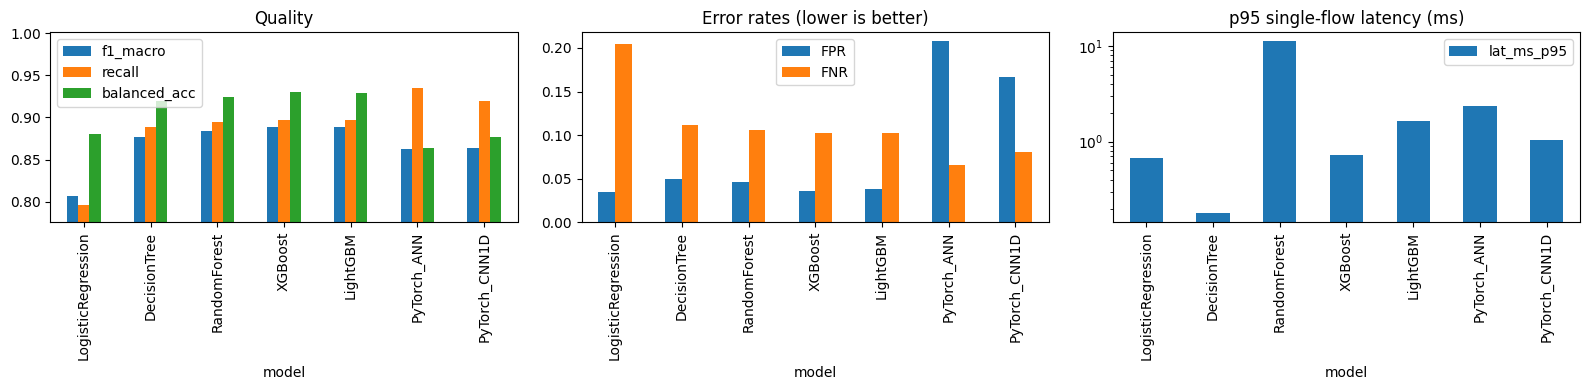

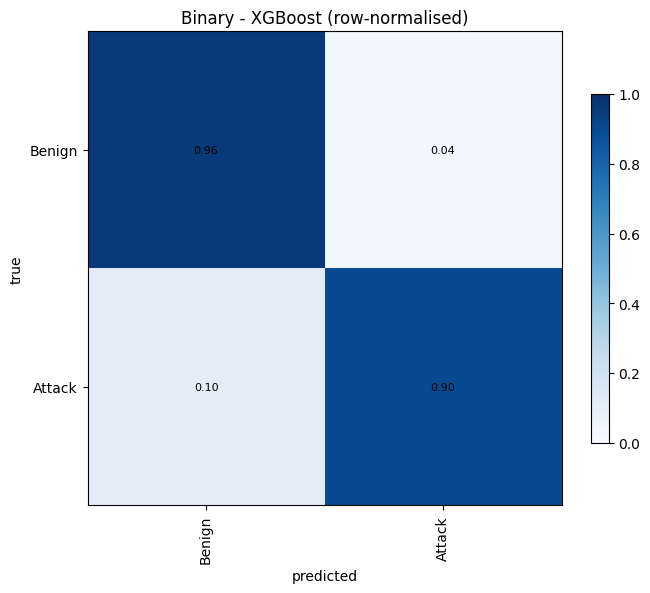

In [44]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
res_bin[['f1_macro', 'recall', 'balanced_acc']].plot.bar(ax=ax[0], ylim=(res_bin[['f1_macro','recall','balanced_acc']].min().min() - .02, 1.001), title='Quality');
res_bin[['FPR', 'FNR']].plot.bar(ax=ax[1], title='Error rates (lower is better)')
res_bin[['lat_ms_p95']].plot.bar(ax=ax[2], title='p95 single-flow latency (ms)', logy=True)
plt.tight_layout(); plt.show()
plot_cm(cms_bin[best_bin], bin_names, f'Binary - {best_bin} (row-normalised)', 'cm_binary.png')

In [45]:
best_model_b = fit_bin[best_bin]
proba = best_model_b.predict_proba(Xte)[:, 1]
rows = []
for th in (0.3, 0.4, 0.5, 0.6, 0.7):
    m, _ = full_metrics(yte_b, (proba >= th).astype(int), 2)
    rows.append(dict(threshold=th, precision=m['precision'], recall=m['recall'], f1_macro=m['f1_macro'], FPR=m['FPR'], FNR=m['FNR']))
sweep = pd.DataFrame(rows).set_index('threshold'); sweep.round(5).to_csv(REPORTS / 'threshold_sweep_binary.csv')
print(sweep.round(5).to_string())

           precision   recall  f1_macro      FPR      FNR
threshold                                                
0.3          0.96901  0.93200   0.89976  0.09753  0.06800
0.4          0.98042  0.91394   0.89618  0.05974  0.08606
0.5          0.98784  0.89727   0.88925  0.03614  0.10273
0.6          0.99258  0.88024   0.87931  0.02153  0.11976
0.7          0.99612  0.86519   0.86999  0.01102  0.13481


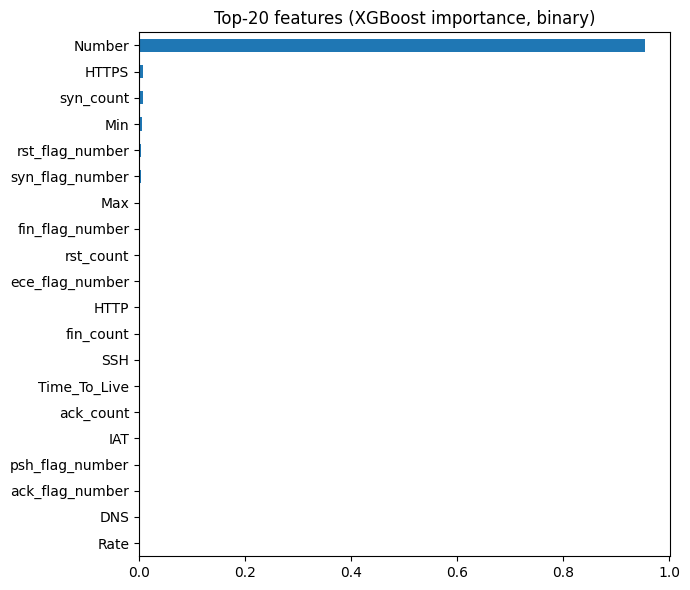

            f1_macro   recall      FPR      FNR   train_s  lat_ms_p95  size_mb
n_features                                                                    
39           0.88849  0.89657  0.03661  0.10343  11.16489     0.68277  3.72731
20           0.88506  0.89173  0.03422  0.10827   6.19930     0.87414  3.62497
10           0.86277  0.86235  0.02613  0.13765   4.62617     0.83363  2.66179


In [46]:
imp = pd.Series(fit_bin['XGBoost'].feature_importances_, index=FEATURES).sort_values(ascending=False)
imp.to_csv(REPORTS / 'feature_importance_xgb_binary.csv')
imp.head(20)[::-1].plot.barh(figsize=(7, 6), title='Top-20 features (XGBoost importance, binary)'); plt.tight_layout(); plt.show()

rows = []
for k in (len(FEATURES), 20, 10):
    cols = [FEATURES.index(f) for f in imp.index[:k]]
    m_ = XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                       eval_metric='logloss', early_stopping_rounds=20, random_state=SEED, **xgb_dev())
    w = compute_sample_weight('balanced', ytr_b)
    t = time.time(); m_.fit(Xtr[:, cols], ytr_b, sample_weight=w, eval_set=[(Xva[:, cols], yva_b)], verbose=False); ts = time.time() - t
    m, _ = full_metrics(yte_b, m_.predict(Xte[:, cols]), 2)
    b = benchmark(m_, Xte[:, cols])
    rows.append(dict(n_features=k, f1_macro=m['f1_macro'], recall=m['recall'], FPR=m['FPR'], FNR=m['FNR'], train_s=ts,
                     lat_ms_p95=b['lat_ms_p95'], size_mb=b['size_mb']))
fr = pd.DataFrame(rows).set_index('n_features'); fr.round(5).to_csv(REPORTS / 'feature_reduction_binary.csv')
print(fr.round(5).to_string())


[family] training RandomForest ...
   macro-F1 0.6932 | recall 0.7311 | FPR 0.0289 | p95 11.87 ms | 286.0 MB | train 172s

[family] training XGBoost ...
   macro-F1 0.7412 | recall 0.7357 | FPR 0.0241 | p95 1.74 ms | 26.8 MB | train 52s

[family] training LightGBM ...
   macro-F1 0.6808 | recall 0.7610 | FPR 0.0297 | p95 1.25 ms | 4.7 MB | train 95s

[family] training PyTorch_ANN ...
   macro-F1 0.6694 | recall 0.6421 | FPR 0.0292 | p95 0.98 ms | 0.1 MB | train 112s

[family] training PyTorch_CNN1D ...
   macro-F1 0.6533 | recall 0.6299 | FPR 0.0308 | p95 1.40 ms | 0.1 MB | train 117s

                accuracy  precision  recall  f1_macro  f1_weighted  balanced_acc     FPR     FNR   train_s  lat_ms_mean  lat_ms_p95  throughput_fps   size_mb
model                                                                                                                                                       
RandomForest     0.8006     0.6817  0.7311    0.6932       0.8099        0.7311  0.0289  0.

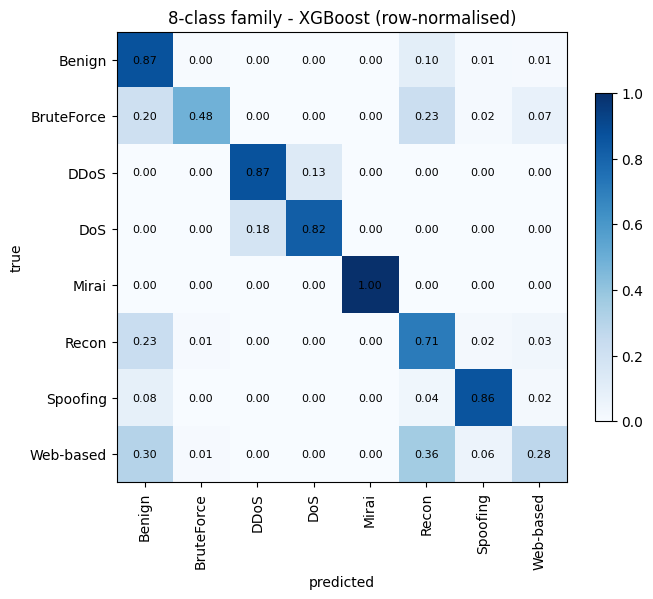

              precision    recall  f1-score   support

      Benign     0.8222    0.8686    0.8448     59826
  BruteForce     0.6055    0.4849    0.5385      1959
        DDoS     0.9276    0.8677    0.8966     80404
         DoS     0.6991    0.8209    0.7551     30033
       Mirai     0.9990    0.9971    0.9980     26762
       Recon     0.7521    0.7103    0.7306     35924
    Spoofing     0.8953    0.8594    0.8770     17060
   Web-based     0.3023    0.2770    0.2891      3643

    accuracy                         0.8419    255611
   macro avg     0.7504    0.7357    0.7412    255611
weighted avg     0.8453    0.8419    0.8424    255611



In [47]:
fam_enc = LabelEncoder().fit(sorted(set(tr.family)))
fam_names = list(fam_enc.classes_)
ytr_f, yva_f, yte_f = (fam_enc.transform(d.family) for d in (tr, va, te))
res_fam, cms_fam, fit_fam = run_task('family', ytr_f, yva_f, yte_f, fam_names, 'family')
best_fam = pick_best(res_fam)
print('\n', res_fam.round(4).to_string())
print('\nBest trade-off model (family):', best_fam)
plot_cm(cms_fam[best_fam], fam_names, f'8-class family - {best_fam} (row-normalised)', 'cm_family.png')
print(classification_report(yte_f, fit_fam[best_fam].predict(Xte), target_names=fam_names, digits=4, zero_division=0))


[finegrained] training RandomForest ...
   macro-F1 0.5829 | recall 0.6121 | FPR 0.0091 | p95 14.27 ms | 257.6 MB | train 103s

[finegrained] training XGBoost ...
   macro-F1 0.6196 | recall 0.6208 | FPR 0.0072 | p95 7.40 ms | 75.5 MB | train 213s

[finegrained] training PyTorch_ANN ...
   macro-F1 0.5502 | recall 0.5517 | FPR 0.0089 | p95 1.30 ms | 0.1 MB | train 108s

[finegrained] training PyTorch_CNN1D ...
   macro-F1 0.5526 | recall 0.5489 | FPR 0.0090 | p95 0.91 ms | 0.1 MB | train 114s

                accuracy  precision  recall  f1_macro  f1_weighted  balanced_acc     FPR     FNR   train_s  lat_ms_mean  lat_ms_p95  throughput_fps   size_mb
model                                                                                                                                                       
RandomForest     0.7022     0.5965  0.6121    0.5829       0.7215        0.6121  0.0091  0.3879  103.1248       8.9231     14.2722    7.177112e+04  257.5776
XGBoost          0.7756     

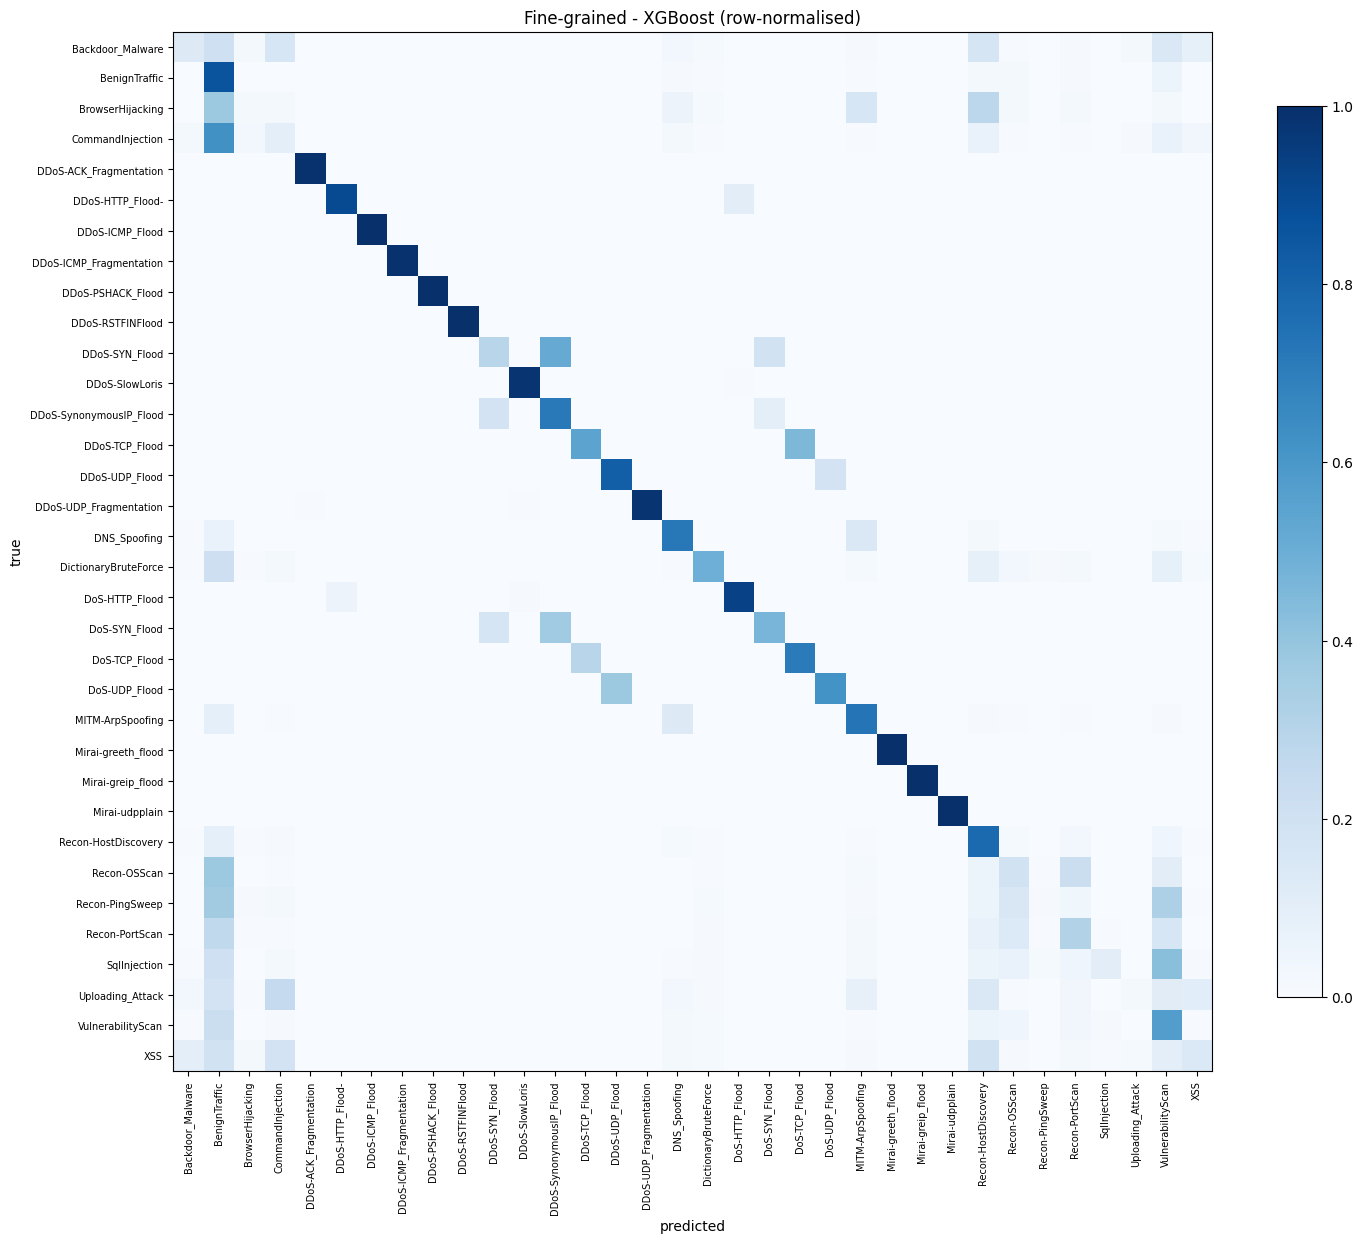


Weakest classes:
                  precision  recall  f1-score  support
Recon-PingSweep       0.011   0.009     0.010    339.0
Uploading_Attack      0.042   0.021     0.028    188.0
BrowserHijacking      0.049   0.023     0.032    811.0
CommandInjection      0.078   0.097     0.086    797.0
XSS                   0.142   0.137     0.139    577.0
Backdoor_Malware      0.156   0.126     0.140    483.0
SqlInjection          0.222   0.105     0.143    787.0
Recon-OSScan          0.373   0.195     0.256   8811.0
DDoS-SYN_Flood        0.461   0.292     0.357   6877.0
Recon-PortScan        0.463   0.311     0.372   8790.0


In [48]:
if RUN_FINEGRAINED:
    lab_enc = LabelEncoder().fit(sorted(set(tr.label)))
    lab_names = list(lab_enc.classes_)
    ytr_l, yva_l, yte_l = (lab_enc.transform(d.label) for d in (tr, va, te))
    res_fg, cms_fg, fit_fg = run_task('finegrained', ytr_l, yva_l, yte_l, lab_names, 'finegrained')
    best_fg = pick_best(res_fg)
    print('\n', res_fg.round(4).to_string())
    print('\nBest trade-off model (fine-grained):', best_fg)
    plot_cm(cms_fg[best_fg], lab_names, f'Fine-grained - {best_fg} (row-normalised)', 'cm_finegrained.png')
    rep = classification_report(yte_l, fit_fg[best_fg].predict(Xte), target_names=lab_names, digits=4, zero_division=0, output_dict=True)
    per_class = pd.DataFrame(rep).T.iloc[:len(lab_names)].sort_values('f1-score')
    per_class.round(4).to_csv(REPORTS / 'per_class_finegrained.csv')
    print('\nWeakest classes:'); print(per_class.head(10).round(3).to_string())
else:
    print('Fine-grained skipped (RUN_FINEGRAINED=False)')

In [49]:
import joblib
def export(model, outdir, meta):
    outdir = MODELS / outdir; outdir.mkdir(parents=True, exist_ok=True)
    to_edge(model); joblib.dump(model, outdir / 'model.joblib')
    (outdir / 'metadata.json').write_text(json.dumps(meta, indent=2, default=float))
    print('exported ->', outdir, f"({os.path.getsize(outdir/'model.joblib')/2**20:.1f} MB)")

best_th = float(sweep.f1_macro.idxmax())
export(fit_bin[best_bin], f'binary/{best_bin}', dict(task='binary', features=FEATURES, classes=bin_names,
       default_threshold=0.5, best_f1_threshold=best_th, metrics=res_bin.loc[best_bin].to_dict()))
export(fit_fam[best_fam], f'multiclass/family_{best_fam}', dict(task='family', features=FEATURES, classes=fam_names,
       metrics=res_fam.loc[best_fam].to_dict()))
if RUN_FINEGRAINED:
    export(fit_fg[best_fg], f'multiclass/finegrained_{best_fg}', dict(task='finegrained', features=FEATURES, classes=lab_names,
           metrics=res_fg.loc[best_fg].to_dict()))
(MODELS / 'label_to_family.json').write_text(json.dumps({l: label_to_family(l) for l in sorted(df.label.unique())}, indent=2))

# sanity check: reload the exported binary model from disk and score the test set
reloaded = joblib.load(MODELS / f'binary/{best_bin}/model.joblib')
m, _ = full_metrics(yte_b, reloaded.predict(Xte), 2)
print('reloaded binary model macro-F1:', round(m['f1_macro'], 4))

exported -> /content/ciciot2023-ids/models/binary/XGBoost (3.7 MB)
exported -> /content/ciciot2023-ids/models/multiclass/family_XGBoost (26.8 MB)
exported -> /content/ciciot2023-ids/models/multiclass/finegrained_XGBoost (75.5 MB)
reloaded binary model macro-F1: 0.8893


In [50]:
final = pd.concat({'binary': res_bin, 'family': res_fam, **({'finegrained': res_fg} if RUN_FINEGRAINED else {})}, names=['task'])
final.round(4).to_csv(REPORTS / 'final_comparison_all_tasks.csv')
print(final[['f1_macro','recall','balanced_acc','FPR','FNR','lat_ms_p95','size_mb','train_s']].round(4).to_string())

report = ['# CICIoT2023 IDS - experiment summary', '',
          f'- files used: {len(files)} | labels: {df.label.nunique()} | sampled rows: {len(df):,} (train {len(tr):,} / val {len(va):,} / test {len(te):,})',
          '- split: first 70% / next 15% / last 15% of each file (time-ordered), exact duplicates removed',
          f'- best binary: **{best_bin}** | best family: **{best_fam}**' + (f' | best fine-grained: **{best_fg}**' if RUN_FINEGRAINED else ''), '',
          final.round(4).to_markdown() if hasattr(final, 'to_markdown') else final.round(4).to_string()]
try: (REPORTS / 'experiment_summary.md').write_text('\n'.join(report))
except Exception as e: (REPORTS / 'experiment_summary.md').write_text('\n'.join(report[:-1]) + '\n' + final.round(4).to_string())

zip_path = shutil.make_archive('/content/ciciot2023_results', 'zip', root_dir=REPO, base_dir='reports')
with zipfile.ZipFile(zip_path, 'a') as z:
    for p in MODELS.rglob('*'):
        if p.is_file(): z.write(p, p.relative_to(REPO))
print('Results zip:', zip_path, f'({os.path.getsize(zip_path)/2**20:.0f} MB)')
try:
    from google.colab import files as colab_files; colab_files.download(zip_path)
except Exception: pass

from google.colab import drive; drive.mount('/content/drive')
shutil.copy(zip_path, '/content/drive/MyDrive/'); shutil.copy(cache_file, '/content/drive/MyDrive/')

                                f1_macro  recall  balanced_acc     FPR     FNR  lat_ms_p95   size_mb   train_s
task        model                                                                                             
binary      LogisticRegression    0.8073  0.7958        0.8808  0.0342  0.2042      0.6695    0.0023    9.8855
            DecisionTree          0.8773  0.8886        0.9195  0.0496  0.1114      0.1778    1.2999   16.3757
            RandomForest          0.8835  0.8944        0.9241  0.0461  0.1056     11.2220   87.6809  143.6791
            XGBoost               0.8893  0.8973        0.9306  0.0361  0.1027      0.7214    3.7028   11.4809
            LightGBM              0.8887  0.8975        0.9295  0.0384  0.1025      1.6469    2.6202   42.9734
            PyTorch_ANN           0.8630  0.9349        0.8637  0.2076  0.0651      2.3616    0.0615  111.5261
            PyTorch_CNN1D         0.8638  0.9192        0.8762  0.1667  0.0808      1.0502    0.0787  115.3179
f

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


'/content/drive/MyDrive/sampled_ciciot2023.parquet'

In [51]:
from sklearn.metrics import roc_auc_score, average_precision_score
m_ = fit_bin['XGBoost']

# 1) Which attacks does the binary model miss? (Benign row = false-alarm rate)
t = te[['family','label']].copy(); t['flagged_attack'] = m_.predict(Xte)
det = t.groupby(['family','label']).flagged_attack.agg(rate='mean', n='size').sort_values('rate')
print(det.round(3).to_string())

# 2) Ranking quality, independent of the 0.5 threshold
p = m_.predict_proba(Xte)[:,1]
print(f"\nROC-AUC {roc_auc_score(te.is_attack,p):.4f} | PR-AUC {average_precision_score(te.is_attack,p):.4f}")

# 3) Identical feature vectors carrying different labels (irreducible error)
k = pd.util.hash_pandas_object(df[FEATURES], index=False)
g = df.assign(k=k).groupby('k')
for col in ('label','family','is_attack'):
    print(f"rows sharing an exact feature vector with another {col}: {(g[col].transform('nunique')>1).mean():.2%}")

# 4) Does it still work without 'Number'?
keep = [i for i,f in enumerate(FEATURES) if f != 'Number']
w = compute_sample_weight('balanced', ytr_b)
m2 = XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                   eval_metric='logloss', early_stopping_rounds=20, random_state=SEED, **xgb_dev())
m2.fit(Xtr[:,keep], ytr_b, sample_weight=w, eval_set=[(Xva[:,keep], yva_b)], verbose=False)
mm,_ = full_metrics(yte_b, m2.predict(Xte[:,keep]), 2)
print(f"\nwithout Number: macro-F1 {mm['f1_macro']:.4f} recall {mm['recall']:.4f} FPR {mm['FPR']:.4f}")
if 'Number' in tr.columns: print(tr.groupby('label')['Number'].median().sort_values().round(1).to_string())

# 5) Threshold picked on VALIDATION, reported once on test
pv = m_.predict_proba(Xva)[:,1]
best_t = max(np.arange(0.1,0.91,0.05), key=lambda th: full_metrics(yva_b,(pv>=th).astype(int),2)[0]['f1_macro'])
mt,_ = full_metrics(yte_b,(p>=best_t).astype(int),2)
print(f"\nval-picked threshold {best_t:.2f} -> test macro-F1 {mt['f1_macro']:.4f} recall {mt['recall']:.4f} FPR {mt['FPR']:.4f}")

                                     rate      n
family     label                                
Benign     BenignTraffic            0.036  59826
Web-based  BrowserHijacking         0.239    811
Recon      Recon-PingSweep          0.413    339
           Recon-OSScan             0.459   8811
           VulnerabilityScan        0.478   8987
           Recon-PortScan           0.558   8790
Web-based  XSS                      0.558    577
           SqlInjection             0.564    787
           Backdoor_Malware         0.607    483
BruteForce DictionaryBruteForce     0.615   1959
Web-based  Uploading_Attack         0.628    188
           CommandInjection         0.681    797
Recon      Recon-HostDiscovery      0.809   8997
Spoofing   MITM-ArpSpoofing         0.844   8136
           DNS_Spoofing             0.876   8924
DDoS       DDoS-SlowLoris           1.000   3514
DoS        DoS-HTTP_Flood           1.000   8963
DDoS       DDoS-UDP_Fragmentation   1.000   8987
DoS        DoS-SYN_F

In [52]:
from sklearn.metrics import roc_auc_score
win = tr.groupby('label')['Number'].median()
same = set(win[win == win[BENIGN_LABEL]].index)
print('window sizes:', win.value_counts().to_dict(), '| attack labels sharing benign window:', len(same)-1)

sel = lambda d: d.label.isin(same).to_numpy()
mtr, mva, mte = sel(tr), sel(va), sel(te)
Xtr2, Xva2, Xte2 = Xtr[mtr], Xva[mva], Xte[mte]
ytr2, yva2, yte2 = ytr_b[mtr], yva_b[mva], yte_b[mte]
print('rows train/val/test:', len(Xtr2), len(Xva2), len(Xte2), '| benign share in test: %.1f%%' % (100*(1-yte2.mean())))

old = fit_bin['XGBoost']
m_old,_ = full_metrics(yte2, old.predict(Xte2), 2)
print(f"(a) old model on fair subset: macro-F1 {m_old['f1_macro']:.4f} recall {m_old['recall']:.4f} FPR {m_old['FPR']:.4f}")

new = XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                    eval_metric='logloss', early_stopping_rounds=20, random_state=SEED, **xgb_dev())
new.fit(Xtr2, ytr2, sample_weight=compute_sample_weight('balanced', ytr2), eval_set=[(Xva2, yva2)], verbose=False)
pn = new.predict_proba(Xte2)[:,1]
m_new,_ = full_metrics(yte2, (pn>=.5).astype(int), 2)
print(f"(b) fair-trained: macro-F1 {m_new['f1_macro']:.4f} recall {m_new['recall']:.4f} FPR {m_new['FPR']:.4f} | ROC-AUC {roc_auc_score(yte2,pn):.4f}")

pv = new.predict_proba(Xva2)[:,1]
rows=[]
for target in (0.01, 0.02, 0.05):
    thr = np.quantile(pv[yva2==0], 1-target)
    m,_ = full_metrics(yte2, (pn>thr).astype(int), 2)
    rows.append(dict(target_FPR=target, test_FPR=m['FPR'], test_recall=m['recall'], precision=m['precision']))
print('(c) thresholds picked on val:'); print(pd.DataFrame(rows).round(4).to_string(index=False))

thr2 = np.quantile(pv[yva2==0], 0.98)
tt = te[mte][['label']].copy(); tt['flagged'] = (pn>thr2).astype(int)
print('(d) detection per label at FPR~2%:'); print(tt.groupby('label').flagged.agg(rate='mean', n='size').sort_values('rate').round(3).to_string())

window sizes: {100.0: 19, 10.0: 15} | attack labels sharing benign window: 14
rows train/val/test: 554122 118290 118412 | benign share in test: 50.5%
(a) old model on fair subset: macro-F1 0.8068 recall 0.6567 FPR 0.0361
(b) fair-trained: macro-F1 0.8403 recall 0.8082 FPR 0.1277 | ROC-AUC 0.9215
(c) thresholds picked on val:
 target_FPR  test_FPR  test_recall  precision
       0.01    0.0085       0.5364     0.9840
       0.02    0.0172       0.5853     0.9709
       0.05    0.0445       0.6777     0.9372
(d) detection per label at FPR~2%:
                       rate      n
label                             
BenignTraffic         0.017  59826
CommandInjection      0.191    797
BrowserHijacking      0.250    811
Recon-PingSweep       0.277    339
VulnerabilityScan     0.345   8987
Recon-OSScan          0.411   8811
SqlInjection          0.414    787
XSS                   0.421    577
Backdoor_Malware      0.435    483
Uploading_Attack      0.468    188
Recon-PortScan        0.490   8790